# [Lab Session 4](deconvolution.ipynb)

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

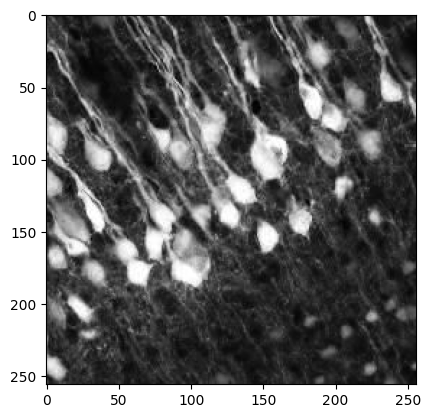

In [5]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')

**[Task 1.]()** Apply the following PSF to the image and then display it.

In [6]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

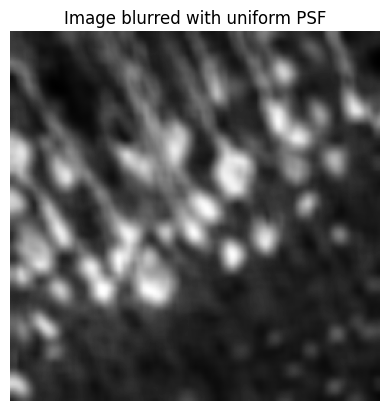

In [7]:
img_psf = conv(img, psf, mode='same', boundary='symm')

plt.imshow(img_psf, 'gray')
plt.title('Image blurred with uniform PSF')
plt.axis('off')
plt.show()

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

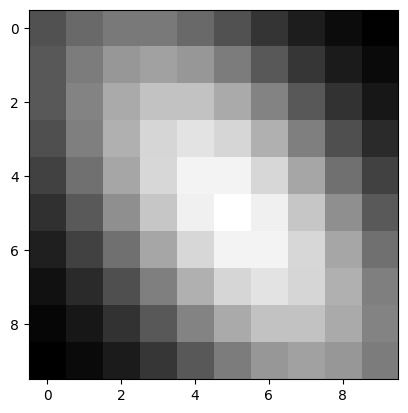

In [8]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'gray')

Apply the second psf to the image:

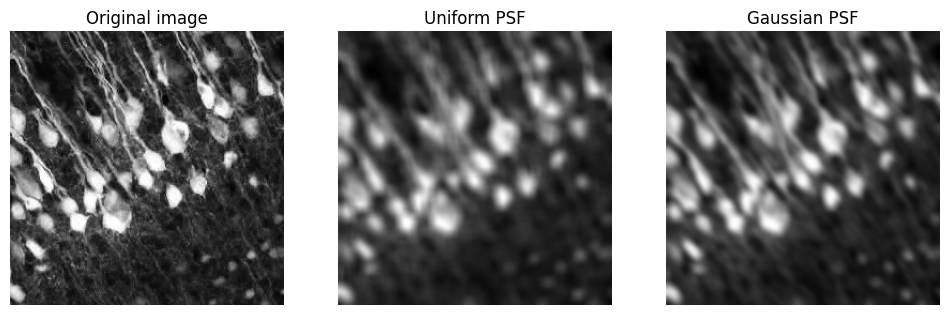

In [9]:
psf_gaussian = create_psf(psf_size)
psf_gaussian = psf_gaussian / psf_gaussian.sum()

img_psf_gaussian = conv(img, psf_gaussian, mode='same', boundary='symm')

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, 'gray')
plt.title('Original image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_psf, 'gray')
plt.title('Uniform PSF')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_psf_gaussian, 'gray')
plt.title('Gaussian PSF')
plt.axis('off')

plt.show()

The two PSFs blur the image differently: 

-> the uniform PSF gives equal weight to all pixels in its window

-> the Gaussian PSF gives more weight to pixels near its center

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [11]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5)
    
    psf_flipped = np.flip(psf)

    for i in range(n_iterations):
        blurred_estimate = conv(img_deconv, psf, mode='same', boundary='symm')

        ratio = image / (blurred_estimate + 1e-12)

        correction = conv(ratio, psf_flipped, mode='same', boundary='symm')

        img_deconv = img_deconv * correction
    
    img_deconv = img_deconv.clip(0,1)
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

In [22]:
deconv_img = richardson_lucy_deconvolution(img_psf, psf, 20)

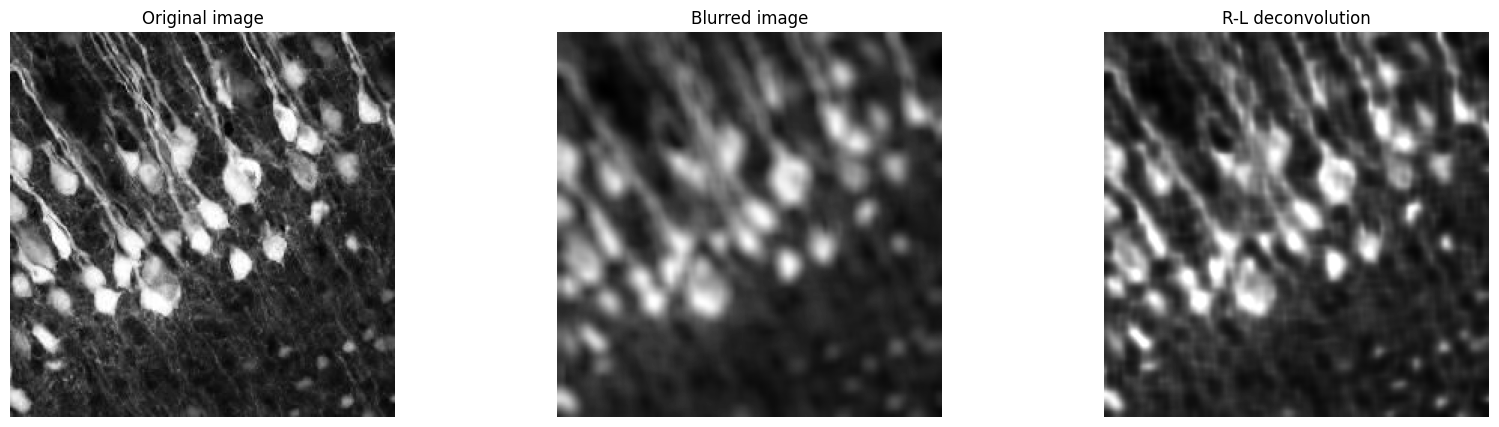

In [23]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_psf, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(deconv_img, 'gray')
plt.title('R-L deconvolution')
plt.show()

Increasing the number of iterations recovered more detail, but too many iterations also amplified noise and created artefacts.

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [24]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

In [25]:
img_psf_noise = np.clip(img_psf_gaussian + noise, 0, 1)

deconv_noise = richardson_lucy_deconvolution(
    img_psf_noise, psf_gaussian, 20
)

Displaying the 3 images:

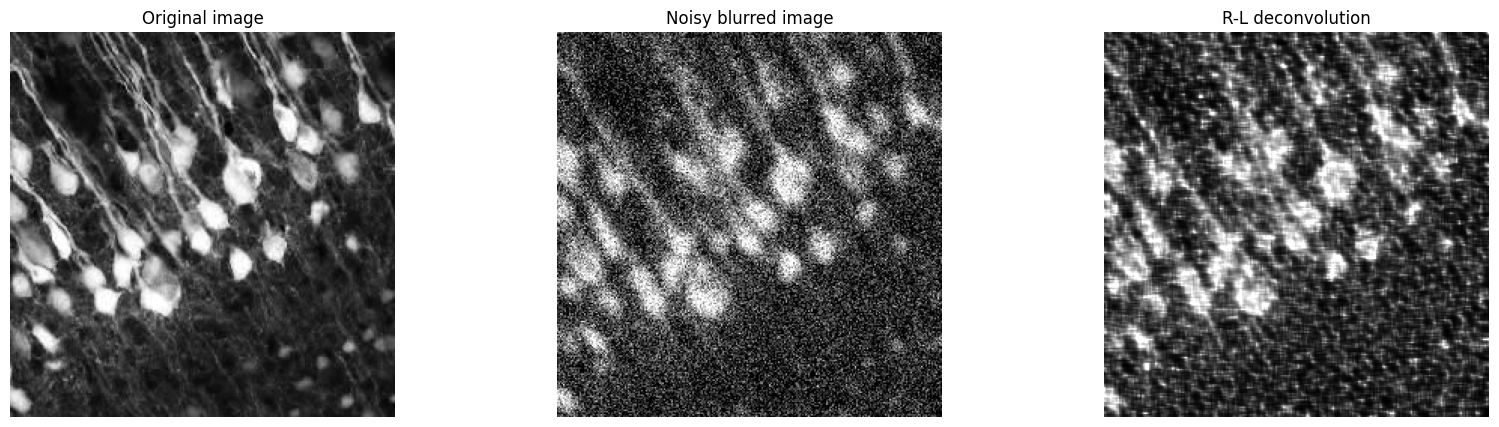

In [26]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, 'gray')
plt.title('Original image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_psf_noise, 'gray')
plt.title('Noisy blurred image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(deconv_noise, 'gray')
plt.title('R-L deconvolution')
plt.axis('off')

plt.show()

Smaller reduce_factor = more noise.


Larger reduce_factor = less noise.

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

In [27]:
deconv_rl = richardson_lucy_deconvolution(img_psf_noise, psf_gaussian, 20)

deconv_wiener = wiener(img_psf_noise, psf_gaussian, balance=2, clip=True)

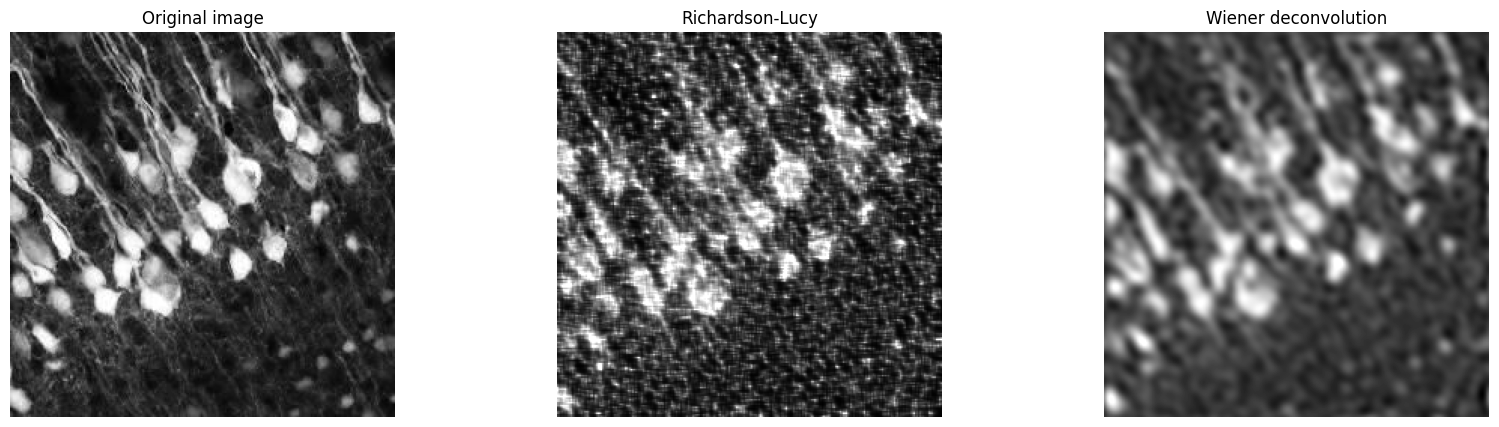

In [28]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, 'gray')
plt.title('Original image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(deconv_rl, 'gray')
plt.title('Richardson-Lucy')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(deconv_wiener, 'gray')
plt.title('Wiener deconvolution')
plt.axis('off')

plt.show()

-> Lower balance values allow more detail but also amplifies noise

-> Higher values suppress noise more strongly but makes the image smoother

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

In [29]:
psf_size = 5

psf_small = np.ones((psf_size, psf_size)) / psf_size**2
psf_gaussian_small = create_psf(psf_size)
psf_gaussian_small = psf_gaussian_small / psf_gaussian_small.sum()

In [30]:
img_psf_small = conv(img, psf_small, mode='same', boundary='symm')
img_psf_gaussian_small = conv(img, psf_gaussian_small, mode='same', boundary='symm')

Finally displaying the results:

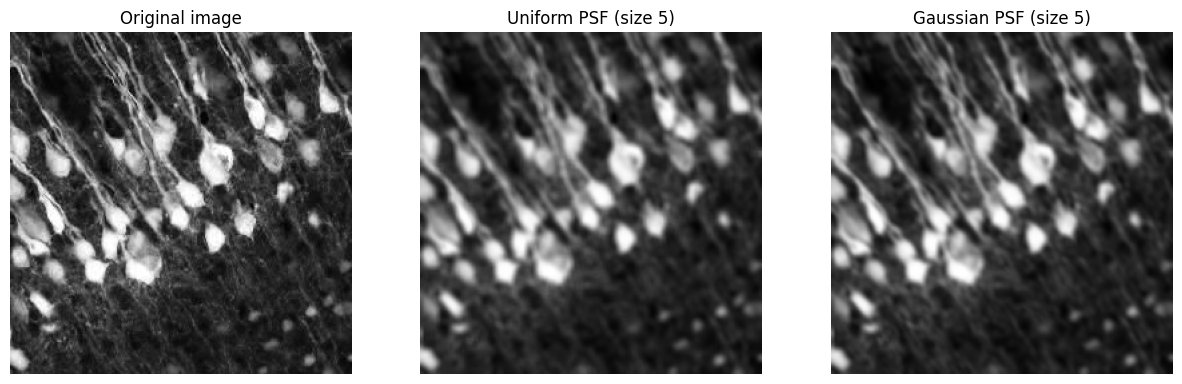

In [31]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, 'gray')
plt.title('Original image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_psf_small, 'gray')
plt.title('Uniform PSF (size 5)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_psf_gaussian_small, 'gray')
plt.title('Gaussian PSF (size 5)')
plt.axis('off')

plt.show()

Repeating the deconvolution:

In [32]:
deconv_small = richardson_lucy_deconvolution(img_psf_small, psf_small, 20)

deconv_gaussian_small = richardson_lucy_deconvolution(
    img_psf_gaussian_small, psf_gaussian_small, 20
)

Displaying the original and both reconstructions:

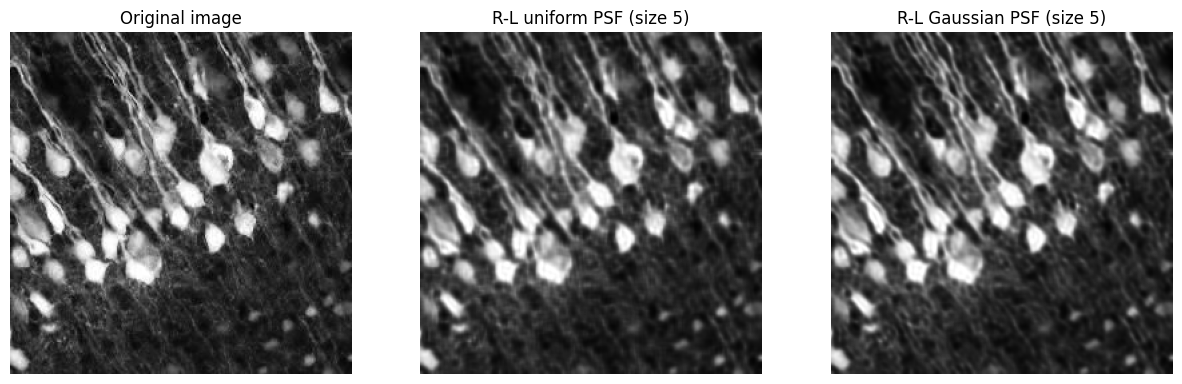

In [33]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, 'gray')
plt.title('Original image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(deconv_small, 'gray')
plt.title('R-L uniform PSF (size 5)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(deconv_gaussian_small, 'gray')
plt.title('R-L Gaussian PSF (size 5)')
plt.axis('off')

plt.show()

There is less blurring with smaller PSFs.

**[Task 8.]()** Use a wrong PSF to restore the image

In [34]:
wrong_uniform = richardson_lucy_deconvolution(
    img_psf_gaussian, psf, 20
)

wrong_gaussian = richardson_lucy_deconvolution(
    img_psf, psf_gaussian, 20
)

Displaying both results:

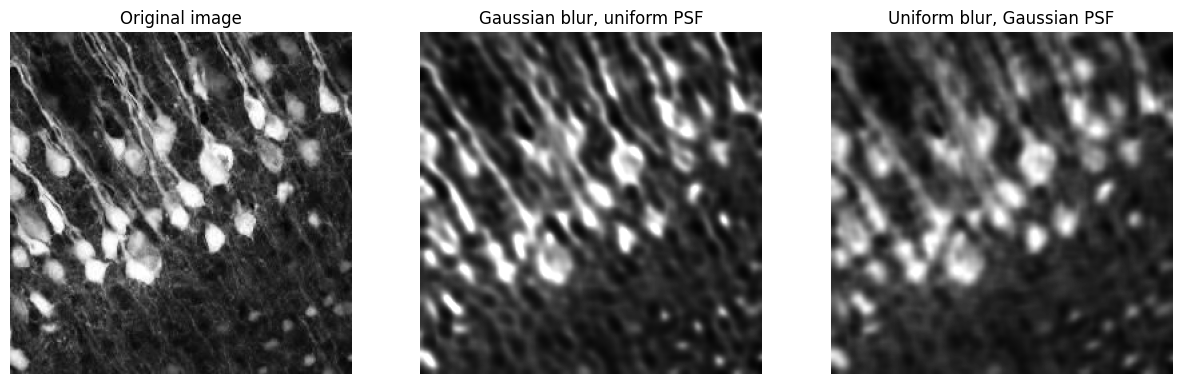

In [35]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, 'gray')
plt.title('Original image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(wrong_uniform, 'gray')
plt.title('Gaussian blur, uniform PSF')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(wrong_gaussian, 'gray')
plt.title('Uniform blur, Gaussian PSF')
plt.axis('off')

plt.show()

Using the wrong PSF produces a poorer reconstruction, because the algorithm assumes a different blurring process than the one that actually affected the image. 

This can result in remaining blur, distorted structures or artefacts.